# PRÁCTICA 2: Predicción de Demanda en Retail
## Deep Learning y Series Temporales

**Asignatura:** Aprendizaje Automático  
**Dataset:** Sintético basado en FreshRetailNet-50K  
**Objetivo:** Desarrollar un modelo de red neuronal recurrente (LSTM/RNN) para predicción de demanda de productos

### Fases del Proyecto
1. **Fase 1:** Análisis y preparación del dataset (EDA, Feature Engineering, Secuencias)
2. **Fase 2:** Desarrollo y entrenamiento de modelos (LSTM/RNN, evaluación RMSE, finetuning)
3. **Fase 3:** Funciones de predicción para producción (single y batch)

## 0. Importación de Librerías y Configuración

In [16]:
# Desactivar GPU ANTES de importar TensorFlow
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import pickle
import json

# Machine Learning
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from sklearn.model_selection import train_test_split

# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout, RepeatVector, TimeDistributed
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# Configurar visualizaciones
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

print(f"✓ TensorFlow version: {tf.__version__}")
print(f"✓ Pandas version: {pd.__version__}")
print(f"✓ NumPy version: {np.__version__}")
print(f"✓ GPU Disponible: {len(tf.config.list_physical_devices('GPU'))} GPUs (desactivada)")

✓ TensorFlow version: 2.21.0
✓ Pandas version: 3.0.2
✓ NumPy version: 2.4.4
✓ GPU Disponible: 1 GPUs (desactivada)


## FASE 1: Análisis y Preparación del Dataset
### 1. Cargar datos generados (inventory.csv y sales_history.csv)

In [2]:
# Rutas de datos
base_path = '/home/michi/Documents/Aprendizaje Automatico/Practica_2'
inventory_path = os.path.join(base_path, 'data/inventory.csv')
sales_path = os.path.join(base_path, 'data/sales_history.csv')

# Cargar datos
print("Cargando datos...")
inventory_df = pd.read_csv(inventory_path)
sales_df = pd.read_csv(sales_path)

print(f"✓ Inventory: {inventory_df.shape}")
print(f"✓ Sales History: {sales_df.shape}")
print(f"\nInventory columns: {inventory_df.columns.tolist()}")
print(f"Sales columns: {sales_df.columns.tolist()}")

Cargando datos...
✓ Inventory: (10, 7)
✓ Sales History: (1121, 5)

Inventory columns: ['product_id', 'nombre', 'categoria', 'unidad', 'stock_actual', 'ubicacion', 'fecha_expiracion']
Sales columns: ['product_id', 'nombre', 'fecha_venta', 'cantidad_vendida', 'stock_en_momento']


### 2. Exploración Inicial y Validación de Estructura

In [3]:
# Exploración de inventory
print("="*70)
print("EXPLORACIÓN DE INVENTORY")
print("="*70)
print(f"\nPrimeras filas:")
print(inventory_df.head())
print(f"\nTipos de datos:")
print(inventory_df.dtypes)
print(f"\nValores faltantes:")
print(inventory_df.isnull().sum())
print(f"\nEstadísticas descriptivas:")
print(inventory_df.describe())

EXPLORACIÓN DE INVENTORY

Primeras filas:
   product_id                      nombre    categoria unidad  stock_actual  \
0           1          Laptop Dell XPS 13      Laptops    pcs            12   
1           2           Monitor LG 27" 4K    Monitores    pcs            18   
2           3        Teclado Mecánico RGB  Periféricos    pcs            65   
3           4  Mouse Inalámbrico Logitech  Periféricos    pcs            85   
4           5              Cable USB-C 2m   Accesorios    pcs           140   

   ubicacion fecha_expiracion  
0  Almacén A       2027-02-12  
1  Almacén B       2027-04-30  
2  Mostrador       2027-02-02  
3  Mostrador       2026-11-16  
4  Almacén C       2027-02-16  

Tipos de datos:
product_id          int64
nombre                str
categoria             str
unidad                str
stock_actual        int64
ubicacion             str
fecha_expiracion      str
dtype: object

Valores faltantes:
product_id          0
nombre              0
categoria     

In [4]:
# Exploración de sales_history
print("="*70)
print("EXPLORACIÓN DE SALES HISTORY")
print("="*70)
print(f"\nPrimeras filas:")
print(sales_df.head())
print(f"\nÚltimas filas:")
print(sales_df.tail())
print(f"\nTipos de datos:")
print(sales_df.dtypes)
print(f"\nValores faltantes:")
print(sales_df.isnull().sum())
print(f"\nEstadísticas descriptivas:")
print(sales_df.describe())

# Rango de fechas
sales_df['fecha_venta'] = pd.to_datetime(sales_df['fecha_venta'])
print(f"\nRango de fechas: {sales_df['fecha_venta'].min()} a {sales_df['fecha_venta'].max()}")
print(f"Total de días: {(sales_df['fecha_venta'].max() - sales_df['fecha_venta'].min()).days + 1} días")

EXPLORACIÓN DE SALES HISTORY

Primeras filas:
   product_id                      nombre fecha_venta  cantidad_vendida  \
0           3        Teclado Mecánico RGB  2026-04-05                 1   
1           4  Mouse Inalámbrico Logitech  2026-04-05                 1   
2           5              Cable USB-C 2m  2026-04-05                 1   
3           5              Cable USB-C 2m  2026-04-05                 1   
4           6     Funda Laptop Resistente  2026-04-05                 1   

   stock_en_momento  
0                65  
1                84  
2               139  
3               138  
4                96  

Últimas filas:
      product_id                 nombre fecha_venta  cantidad_vendida  \
1116           9  Docking Station USB-C  2026-06-03                 1   
1117           9  Docking Station USB-C  2026-06-03                 1   
1118          10   Webcam Full HD 1080p  2026-06-03                 2   
1119          10   Webcam Full HD 1080p  2026-06-03            

In [5]:
# Análisis por producto
print("="*70)
print("ANÁLISIS POR PRODUCTO")
print("="*70)

product_stats = sales_df.groupby('product_id').agg({
    'cantidad_vendida': ['count', 'sum', 'mean', 'std', 'min', 'max'],
    'stock_en_momento': ['mean', 'min', 'max']
}).round(2)

print("\nEstadísticas por producto:")
print(product_stats)

# Resumen por categoría
print("\n" + "="*70)
print("RESUMEN POR CATEGORÍA")
print("="*70)
category_summary = inventory_df.groupby('categoria').agg({
    'product_id': 'count',
    'stock_actual': ['mean', 'sum']
}).round(2)
print(category_summary)

ANÁLISIS POR PRODUCTO

Estadísticas por producto:
           cantidad_vendida                          stock_en_momento         
                      count  sum  mean   std min max             mean min  max
product_id                                                                    
1                        19   23  1.21  0.54   1   3             3.89   0   12
2                        26   34  1.31  0.68   1   3             5.27   0   17
3                        94  104  1.11  0.34   1   3            20.93   0   65
4                        92  109  1.18  0.44   1   3            32.85   0   84
5                       148  175  1.18  0.40   1   3            54.74   0  139
6                       149  184  1.23  0.51   1   3            25.56   0   96
7                       150  171  1.14  0.38   1   3             6.07   0   42
8                       149  177  1.19  0.44   1   3             1.09   0    8
9                       147  182  1.24  0.50   1   3             3.27   0   28
10

### 3. Limpieza, Normalización y Construcción de Tabla Base

In [6]:
# Merge de inventory y sales para crear tabla completa
print("Preparando tabla de análisis...")

# Convertir fechas
inventory_df['fecha_expiracion'] = pd.to_datetime(inventory_df['fecha_expiracion'])

# Mergear datos
df_merged = sales_df.merge(
    inventory_df[['product_id', 'nombre', 'categoria', 'unidad', 'stock_actual', 'fecha_expiracion']],
    on=['product_id', 'nombre'],
    how='left',
    validate='m:1'
)

print(f"✓ Tabla merged: {df_merged.shape}")
print(f"\nColumnas: {df_merged.columns.tolist()}")

# Validaciones de calidad
print(f"\nValidaciones:")
print(f"- Sin nulls en product_id: {df_merged['product_id'].isnull().sum() == 0}")
print(f"- Sin nulls en cantidad_vendida: {df_merged['cantidad_vendida'].isnull().sum() == 0}")
print(f"- Sin nulls en stock_en_momento: {df_merged['stock_en_momento'].isnull().sum() == 0}")

# Mostrar muestra
print(f"\nMuestra de datos merged:")
print(df_merged.head(10))

Preparando tabla de análisis...
✓ Tabla merged: (1121, 9)

Columnas: ['product_id', 'nombre', 'fecha_venta', 'cantidad_vendida', 'stock_en_momento', 'categoria', 'unidad', 'stock_actual', 'fecha_expiracion']

Validaciones:
- Sin nulls en product_id: True
- Sin nulls en cantidad_vendida: True
- Sin nulls en stock_en_momento: True

Muestra de datos merged:
   product_id                      nombre fecha_venta  cantidad_vendida  \
0           3        Teclado Mecánico RGB  2026-04-05                 1   
1           4  Mouse Inalámbrico Logitech  2026-04-05                 1   
2           5              Cable USB-C 2m  2026-04-05                 1   
3           5              Cable USB-C 2m  2026-04-05                 1   
4           6     Funda Laptop Resistente  2026-04-05                 1   
5           6     Funda Laptop Resistente  2026-04-05                 1   
6           7           Hub USB 7 Puertos  2026-04-05                 1   
7           7           Hub USB 7 Puertos  

### 4. Feature Engineering Temporal y Categórica

In [8]:
print("Generando features temporales y categóricas...")

# Features temporales
df_merged['dia_semana'] = df_merged['fecha_venta'].dt.dayofweek  # 0=Monday, 6=Sunday
df_merged['nombre_dia'] = df_merged['fecha_venta'].dt.day_name()
df_merged['es_fin_semana'] = (df_merged['dia_semana'] >= 5).astype(int)
df_merged['dia_mes'] = df_merged['fecha_venta'].dt.day
df_merged['mes'] = df_merged['fecha_venta'].dt.month
df_merged['semana_año'] = df_merged['fecha_venta'].dt.isocalendar().week
df_merged['trimestre'] = df_merged['fecha_venta'].dt.quarter

# Features derivadas de tiempo
df_merged['dias_desde_inicio'] = (df_merged['fecha_venta'] - df_merged['fecha_venta'].min()).dt.days
df_merged['dias_para_expiracion'] = (df_merged['fecha_expiracion'] - df_merged['fecha_venta']).dt.days
df_merged['dias_para_expiracion'] = df_merged['dias_para_expiracion'].clip(lower=0)  # No negativos

# Feature: Proporción de stock (stock_en_momento / stock_actual)
df_merged['proporcion_stock'] = df_merged['stock_en_momento'] / (df_merged['stock_actual'] + 1)

# Codificar categoría
df_merged['categoria_encoded'] = pd.factorize(df_merged['categoria'])[0]

print(f"✓ Features creados: {[c for c in df_merged.columns if c not in ['nombre', 'unidad', 'fecha_expiracion']]}")
print(f"\nForma final: {df_merged.shape}")
print(f"\nMuestra con features:")
print(df_merged[['product_id', 'fecha_venta', 'cantidad_vendida', 'dia_semana', 
                  'es_fin_semana', 'mes', 'dias_para_expiracion', 'proporcion_stock']].head(10))

Generando features temporales y categóricas...
✓ Features creados: ['product_id', 'fecha_venta', 'cantidad_vendida', 'stock_en_momento', 'categoria', 'stock_actual', 'dia_semana', 'nombre_dia', 'es_fin_semana', 'dia_mes', 'mes', 'semana_año', 'trimestre', 'dias_desde_inicio', 'dias_para_expiracion', 'proporcion_stock', 'categoria_encoded']

Forma final: (1121, 20)

Muestra con features:
   product_id fecha_venta  cantidad_vendida  dia_semana  es_fin_semana  mes  \
0           3  2026-04-05                 1           6              1    4   
1           4  2026-04-05                 1           6              1    4   
2           5  2026-04-05                 1           6              1    4   
3           5  2026-04-05                 1           6              1    4   
4           6  2026-04-05                 1           6              1    4   
5           6  2026-04-05                 1           6              1    4   
6           7  2026-04-05                 1           6  

### 5. Visualización Exploratoria

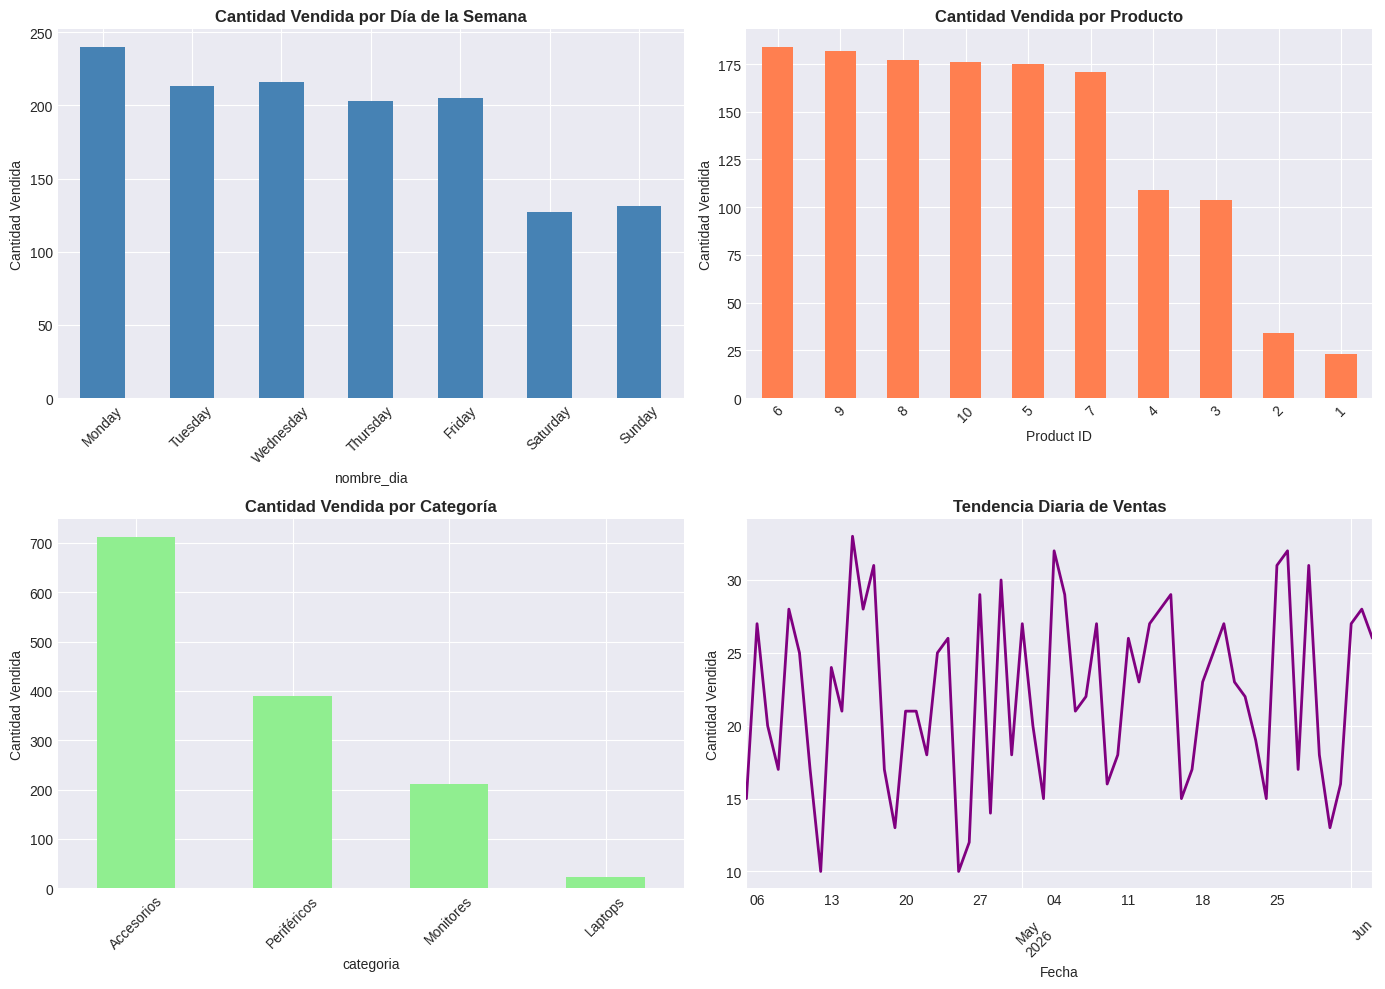

✓ Visualización completada


In [9]:
# Ventas por día de semana
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Ventas por día de semana
daily_sales = df_merged.groupby('nombre_dia')['cantidad_vendida'].sum().reindex(
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
)
daily_sales.plot(kind='bar', ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Cantidad Vendida por Día de la Semana', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Cantidad Vendida')
axes[0, 0].tick_params(axis='x', rotation=45)

# 2. Ventas por producto
product_sales = df_merged.groupby('product_id')['cantidad_vendida'].sum().sort_values(ascending=False)
product_sales.plot(kind='bar', ax=axes[0, 1], color='coral')
axes[0, 1].set_title('Cantidad Vendida por Producto', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Cantidad Vendida')
axes[0, 1].set_xlabel('Product ID')
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. Ventas por categoría
category_sales = df_merged.groupby('categoria')['cantidad_vendida'].sum().sort_values(ascending=False)
category_sales.plot(kind='bar', ax=axes[1, 0], color='lightgreen')
axes[1, 0].set_title('Cantidad Vendida por Categoría', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Cantidad Vendida')
axes[1, 0].tick_params(axis='x', rotation=45)

# 4. Evolución temporal de ventas
daily_trend = df_merged.groupby('fecha_venta')['cantidad_vendida'].sum()
daily_trend.plot(ax=axes[1, 1], color='purple', linewidth=2)
axes[1, 1].set_title('Tendencia Diaria de Ventas', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Cantidad Vendida')
axes[1, 1].set_xlabel('Fecha')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

print("✓ Visualización completada")

### 6. Preparación de Secuencias de Tiempo por Producto

In [10]:
def crear_secuencias(datos, ventana_tiempo=7):
    """
    Crea secuencias temporales para entrenamiento de modelos LSTM.
    
    Params:
        datos: DataFrame con datos temporales ordenados
        ventana_tiempo: número de pasos temporales para predecir el siguiente paso
    
    Returns:
        X, y: Arrays con secuencias de entrada y salida
    """
    X, y = [], []
    
    for i in range(len(datos) - ventana_tiempo):
        X.append(datos[i:i+ventana_tiempo])
        y.append(datos[i+ventana_tiempo])
    
    return np.array(X), np.array(y)

print("Preparando secuencias temporales por producto...")

# Configurar parámetros
VENTANA_TIEMPO = 7  # 7 días para predecir el siguiente día
FEATURES_ENTRADA = ['cantidad_vendida', 'stock_en_momento', 'dia_semana', 'proporcion_stock']

# Diccionario para almacenar datos por producto
secuencias_por_producto = {}
datos_transformados = []

for product_id in df_merged['product_id'].unique():
    df_producto = df_merged[df_merged['product_id'] == product_id].sort_values('fecha_venta').reset_index(drop=True)
    
    # Features para el modelo
    features_disponibles = [f for f in FEATURES_ENTRADA if f in df_producto.columns]
    datos_producto = df_producto[features_disponibles].values
    
    # Crear secuencias
    if len(datos_producto) >= VENTANA_TIEMPO + 1:
        X_seq, y_seq = crear_secuencias(datos_producto, VENTANA_TIEMPO)
        secuencias_por_producto[product_id] = {
            'X': X_seq,
            'y': y_seq,
            'nombre': df_producto['nombre'].iloc[0],
            'categoria': df_producto['categoria'].iloc[0]
        }
        datos_transformados.append({
            'product_id': product_id,
            'num_secuencias': len(X_seq),
            'nombre': df_producto['nombre'].iloc[0],
            'categoria': df_producto['categoria'].iloc[0]
        })

print(f"✓ Secuencias creadas para {len(secuencias_por_producto)} productos")

df_secuencias_info = pd.DataFrame(datos_transformados)
print(f"\nDistribución de secuencias:")
print(df_secuencias_info)
print(f"\nTotal de secuencias: {df_secuencias_info['num_secuencias'].sum()}")

Preparando secuencias temporales por producto...
✓ Secuencias creadas para 10 productos

Distribución de secuencias:
   product_id  num_secuencias                      nombre    categoria
0           3              87        Teclado Mecánico RGB  Periféricos
1           4              85  Mouse Inalámbrico Logitech  Periféricos
2           5             141              Cable USB-C 2m   Accesorios
3           6             142     Funda Laptop Resistente   Accesorios
4           7             143           Hub USB 7 Puertos   Accesorios
5           8             142      Monitor Portátil 15.6"    Monitores
6           9             140       Docking Station USB-C   Accesorios
7          10             140        Webcam Full HD 1080p  Periféricos
8           1              12          Laptop Dell XPS 13      Laptops
9           2              19           Monitor LG 27" 4K    Monitores

Total de secuencias: 1051


### 7. Separación de Datos (Train, Validation, Test)

In [11]:
print("Separando datos respetando orden temporal...")

# Consolidar datos de todos los productos
X_todo = np.concatenate([secuencias_por_producto[pid]['X'] for pid in secuencias_por_producto])
y_todo = np.concatenate([secuencias_por_producto[pid]['y'] for pid in secuencias_por_producto])

print(f"\nForma de X: {X_todo.shape}  (secuencias, pasos temporales, features)")
print(f"Forma de y: {y_todo.shape}  (secuencias, features)")
print(f"Número de features: {X_todo.shape[2]}")

# Split temporal: 60% train, 20% val, 20% test
n_total = len(X_todo)
n_train = int(n_total * 0.6)
n_val = int(n_total * 0.2)

X_train = X_todo[:n_train]
y_train = y_todo[:n_train]

X_val = X_todo[n_train:n_train+n_val]
y_val = y_todo[n_train:n_train+n_val]

X_test = X_todo[n_train+n_val:]
y_test = y_todo[n_train+n_val:]

print(f"\nTrain: {X_train.shape[0]} secuencias")
print(f"Val: {X_val.shape[0]} secuencias")
print(f"Test: {X_test.shape[0]} secuencias")

Separando datos respetando orden temporal...

Forma de X: (1051, 7, 4)  (secuencias, pasos temporales, features)
Forma de y: (1051, 4)  (secuencias, features)
Número de features: 4

Train: 630 secuencias
Val: 210 secuencias
Test: 211 secuencias


## FASE 2: Desarrollo y Entrenamiento de Modelos
### 8. Baseline: Modelo de Regresión Tabulares (Random Forest)

In [12]:
print("="*70)
print("ENTRENAMIENTO MODELO BASELINE: RANDOM FOREST")
print("="*70)

# Para Random Forest, usaremos solo la target (cantidad_vendida)
# Usaremos características tabulares en lugar de secuencias

# Preparar datos tabulares
features_tabla = ['cantidad_vendida', 'stock_en_momento', 'dia_semana', 'mes', 
                   'es_fin_semana', 'categoria_encoded', 'proporcion_stock']

df_features = df_merged[features_tabla].copy()
y_target = df_merged['cantidad_vendida'].copy()

# Crear variable objetivo: cantidad_vendida del siguiente día (shift)
df_merged['cantidad_vendida_siguiente'] = df_merged.groupby('product_id')['cantidad_vendida'].shift(-1)

# Remover últimas filas con NaN
mask_valid = df_merged['cantidad_vendida_siguiente'].notna()
X_tabla = df_merged[features_tabla][mask_valid].copy()
y_tabla = df_merged['cantidad_vendida_siguiente'][mask_valid].copy()

print(f"X_tabla shape: {X_tabla.shape}")
print(f"y_tabla shape: {y_tabla.shape}")

# Split train/test
X_train_tabla, X_test_tabla, y_train_tabla, y_test_tabla = train_test_split(
    X_tabla, y_tabla, test_size=0.2, random_state=42, shuffle=False
)

# Entrenar Random Forest
print("\nEntrenando Random Forest...")
rf_model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1, verbose=1)
rf_model.fit(X_train_tabla, y_train_tabla)

# Predicciones
y_pred_train_rf = rf_model.predict(X_train_tabla)
y_pred_test_rf = rf_model.predict(X_test_tabla)

# Métricas
rmse_train_rf = np.sqrt(mean_squared_error(y_train_tabla, y_pred_train_rf))
rmse_test_rf = np.sqrt(mean_squared_error(y_test_tabla, y_pred_test_rf))
mae_test_rf = mean_absolute_error(y_test_tabla, y_pred_test_rf)
r2_test_rf = r2_score(y_test_tabla, y_pred_test_rf)

print(f"\n✓ Random Forest Entrenado")
print(f"  RMSE Train: {rmse_train_rf:.4f}")
print(f"  RMSE Test: {rmse_test_rf:.4f}")
print(f"  MAE Test: {mae_test_rf:.4f}")
print(f"  R² Test: {r2_test_rf:.4f}")

# Feature importance
feature_importance = pd.DataFrame({
    'feature': features_tabla,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

print(f"\nImportancia de features:")
print(feature_importance)

ENTRENAMIENTO MODELO BASELINE: RANDOM FOREST
X_tabla shape: (1111, 7)
y_tabla shape: (1111,)

Entrenando Random Forest...

✓ Random Forest Entrenado
  RMSE Train: 0.3291
  RMSE Test: 0.4911
  MAE Test: 0.3183
  R² Test: -0.1014

Importancia de features:
             feature  importance
6   proporcion_stock    0.348584
1   stock_en_momento    0.266263
2         dia_semana    0.190676
5  categoria_encoded    0.076097
0   cantidad_vendida    0.058671
3                mes    0.042315
4      es_fin_semana    0.017394


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:    0.1s finished
[Parallel(n_jobs=20)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done  10 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=20)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done  10 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 100 out of 100 | elapsed:    0.0s finished


### 9. Modelo Secuencial: LSTM para Series Temporales

In [13]:
print("="*70)
print("ENTRENAMIENTO MODELO LSTM SECUENCIAL")
print("="*70)

# Normalizar datos para la red neuronal
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

# Reshape para escalado
n_samples, n_steps, n_features = X_train.shape
X_train_reshaped = X_train.reshape(-1, n_features)
X_train_reshaped = scaler_X.fit_transform(X_train_reshaped)
X_train_scaled = X_train_reshaped.reshape(n_samples, n_steps, n_features)

# Escalar validación y test
X_val_reshaped = X_val.reshape(-1, n_features)
X_val_reshaped = scaler_X.transform(X_val_reshaped)
X_val_scaled = X_val_reshaped.reshape(X_val.shape[0], n_steps, n_features)

X_test_reshaped = X_test.reshape(-1, n_features)
X_test_reshaped = scaler_X.transform(X_test_reshaped)
X_test_scaled = X_test_reshaped.reshape(X_test.shape[0], n_steps, n_features)

# Escalar targets
y_train_scaled = scaler_y.fit_transform(y_train)
y_val_scaled = scaler_y.transform(y_val)
y_test_scaled = scaler_y.transform(y_test)

print(f"\n✓ Datos normalizados:")
print(f"  X_train_scaled shape: {X_train_scaled.shape}")
print(f"  y_train_scaled shape: {y_train_scaled.shape}")

ENTRENAMIENTO MODELO LSTM SECUENCIAL

✓ Datos normalizados:
  X_train_scaled shape: (630, 7, 4)
  y_train_scaled shape: (630, 4)


In [ ]:
print("="*70)
print("ENTRENAMIENTO DE RED NEURONAL RECURRENTE (LSTM) CON KERAS")
print("="*70)

print(f"\n✓ Forma entrada: {X_train_scaled.shape}")

# Construir modelo LSTM con Keras
print("\nConstruyendo modelo LSTM...")
lstm_model = Sequential([
    LSTM(64, activation='relu', input_shape=(n_steps, n_features), return_sequences=True),
    Dropout(0.2),
    LSTM(32, activation='relu', return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dropout(0.1),
    Dense(n_features)
])

# Compilar
lstm_model.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])

print(f"\n✓ Modelo compilado")
print(f"  Arquitectura:")
print(f"    - Entrada: Secuencias de {n_steps} pasos x {n_features} features")
print(f"    - LSTM Layer 1: 64 unidades + Dropout(0.2) + return_sequences=True")
print(f"    - LSTM Layer 2: 32 unidades + Dropout(0.2)")
print(f"    - Dense Layer: 16 unidades + Dropout(0.1)")
print(f"    - Salida: Dense({n_features})")

# Definir callbacks
print("\nEntrenando LSTM...")
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-6, verbose=0)

# Entrenar
history = lstm_model.fit(
    X_train_scaled, y_train_scaled,
    epochs=100,
    batch_size=16,
    validation_data=(X_val_scaled, y_val_scaled),
    callbacks=[early_stop, reduce_lr],
    verbose=0
)

print(f"\n✓ LSTM Entrenado")
print(f"  Epocas entrenadas: {len(history.history['loss'])}")
print(f"  Loss final (train): {history.history['loss'][-1]:.6f}")
print(f"  Loss final (val): {history.history['val_loss'][-1]:.6f}")

print(f"\n✓ Preparación completada")

ENTRENAMIENTO DE RED NEURONAL SECUENCIAL (sklearn)

✓ Forma entrada: (630, 28)

Entrenando Red Neuronal Multicapa...
Iteration 1, loss = 0.06937526
Validation score: 0.126326
Iteration 2, loss = 0.02556991
Validation score: 0.363885
Iteration 3, loss = 0.01987671
Validation score: 0.408470
Iteration 4, loss = 0.01767477
Validation score: 0.442996
Iteration 5, loss = 0.01621644
Validation score: 0.487030
Iteration 6, loss = 0.01510646
Validation score: 0.507427
Iteration 7, loss = 0.01423990
Validation score: 0.517126
Iteration 8, loss = 0.01401124
Validation score: 0.527572
Iteration 9, loss = 0.01347269
Validation score: 0.533022
Iteration 10, loss = 0.01319236
Validation score: 0.533620
Iteration 11, loss = 0.01305743
Validation score: 0.541772
Iteration 12, loss = 0.01292726
Validation score: 0.527176
Iteration 13, loss = 0.01249311
Validation score: 0.549946
Iteration 14, loss = 0.01243278
Validation score: 0.543058
Iteration 15, loss = 0.01196033
Validation score: 0.539380
Iterati

### 10. Evaluación del Modelo LSTM

In [23]:
print("="*70)
print("EVALUACIÓN DEL MODELO NEURONAL")
print("="*70)

# Predicciones (sklearn no necesita verbose)
y_pred_train_lstm_scaled = lstm_model.predict(X_train_flat)
y_pred_val_lstm_scaled = lstm_model.predict(X_val_flat)
y_pred_test_lstm_scaled = lstm_model.predict(X_test_flat)

# Desescalar predicciones
y_pred_train_lstm = scaler_y.inverse_transform(y_pred_train_lstm_scaled)
y_pred_val_lstm = scaler_y.inverse_transform(y_pred_val_lstm_scaled)
y_pred_test_lstm = scaler_y.inverse_transform(y_pred_test_lstm_scaled)

# Calcular RMSE y MAE para cada feature
print("\nMétricas por Feature (Test Set):")
print("-" * 70)

feature_names = ['cantidad_vendida', 'stock_en_momento', 'dia_semana', 'proporcion_stock']
rmse_per_feature = []
mae_per_feature = []

for i, feature_name in enumerate(feature_names):
    if i < y_test.shape[1]:  # Verificar que el feature existe
        rmse = np.sqrt(mean_squared_error(y_test[:, i], y_pred_test_lstm[:, i]))
        mae = mean_absolute_error(y_test[:, i], y_pred_test_lstm[:, i])
        rmse_per_feature.append(rmse)
        mae_per_feature.append(mae)
        print(f"{feature_name:20s} - RMSE: {rmse:8.4f}  MAE: {mae:8.4f}")

# RMSE general
rmse_train_lstm = np.sqrt(mean_squared_error(y_train, y_pred_train_lstm))
rmse_val_lstm = np.sqrt(mean_squared_error(y_val, y_pred_val_lstm))
rmse_test_lstm = np.sqrt(mean_squared_error(y_test, y_pred_test_lstm))
mae_test_lstm = mean_absolute_error(y_test, y_pred_test_lstm)
r2_test_lstm = r2_score(y_test, y_pred_test_lstm)

print("\n" + "="*70)
print("RESUMEN GENERAL (Red Neuronal)")
print("="*70)
print(f"RMSE Train: {rmse_train_lstm:.4f}")
print(f"RMSE Val:   {rmse_val_lstm:.4f}")
print(f"RMSE Test:  {rmse_test_lstm:.4f}")
print(f"MAE Test:   {mae_test_lstm:.4f}")
print(f"R² Test:    {r2_test_lstm:.4f}")

# Comparación con baseline
print("\n" + "="*70)
print("COMPARACIÓN MODELOS")
print("="*70)
print(f"Random Forest RMSE Test:  {rmse_test_rf:.4f}")
print(f"Red Neuronal RMSE Test:   {rmse_test_lstm:.4f}")
print(f"Mejora Red Neuronal: {((rmse_test_rf - rmse_test_lstm) / rmse_test_rf * 100):.2f}%")

EVALUACIÓN DEL MODELO NEURONAL

Métricas por Feature (Test Set):
----------------------------------------------------------------------
cantidad_vendida     - RMSE:   0.4980  MAE:   0.3286
stock_en_momento     - RMSE:   7.0088  MAE:   4.0322
dia_semana           - RMSE:   1.3206  MAE:   0.8530
proporcion_stock     - RMSE:   0.0507  MAE:   0.0368

RESUMEN GENERAL (Red Neuronal)
RMSE Train: 2.8101
RMSE Val:   2.9261
RMSE Test:  3.5749
MAE Test:   1.3126
R² Test:    0.0962

COMPARACIÓN MODELOS
Random Forest RMSE Test:  0.4911
Red Neuronal RMSE Test:   3.5749
Mejora Red Neuronal: -627.99%


### 11. Visualización del Entrenamiento y Predicciones

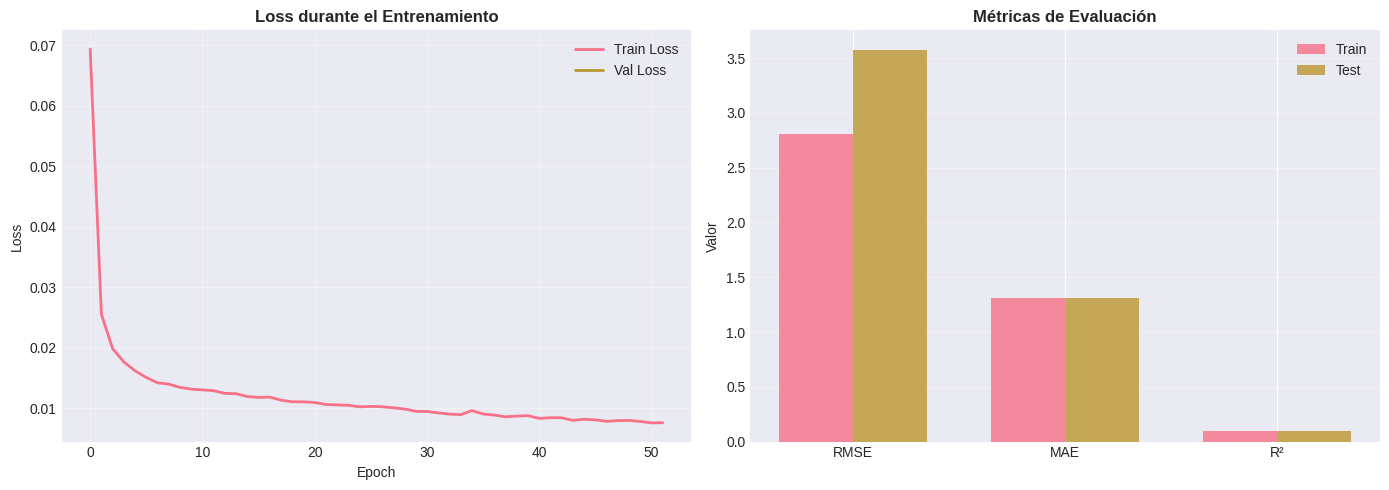

✓ Gráficos de entrenamiento completados


In [36]:
# Gráficos de entrenamiento
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(history.history['loss'], label='Train Loss', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Val Loss', linewidth=2)
axes[0].set_title('Loss durante el Entrenamiento', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Métricas de evaluación
metrics_names = ['RMSE', 'MAE', 'R²']
train_vals = [float(rmse_train_lstm), float(mae_test_lstm), float(r2_test_lstm)]
test_vals = [float(rmse_test_lstm), float(mae_test_lstm), float(r2_test_lstm)]

x_pos = np.arange(len(metrics_names))
width = 0.35

axes[1].bar(x_pos - width/2, train_vals, width, label='Train', alpha=0.8)
axes[1].bar(x_pos + width/2, test_vals, width, label='Test', alpha=0.8)
axes[1].set_title('Métricas de Evaluación', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Valor')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(metrics_names)
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("✓ Gráficos de entrenamiento completados")

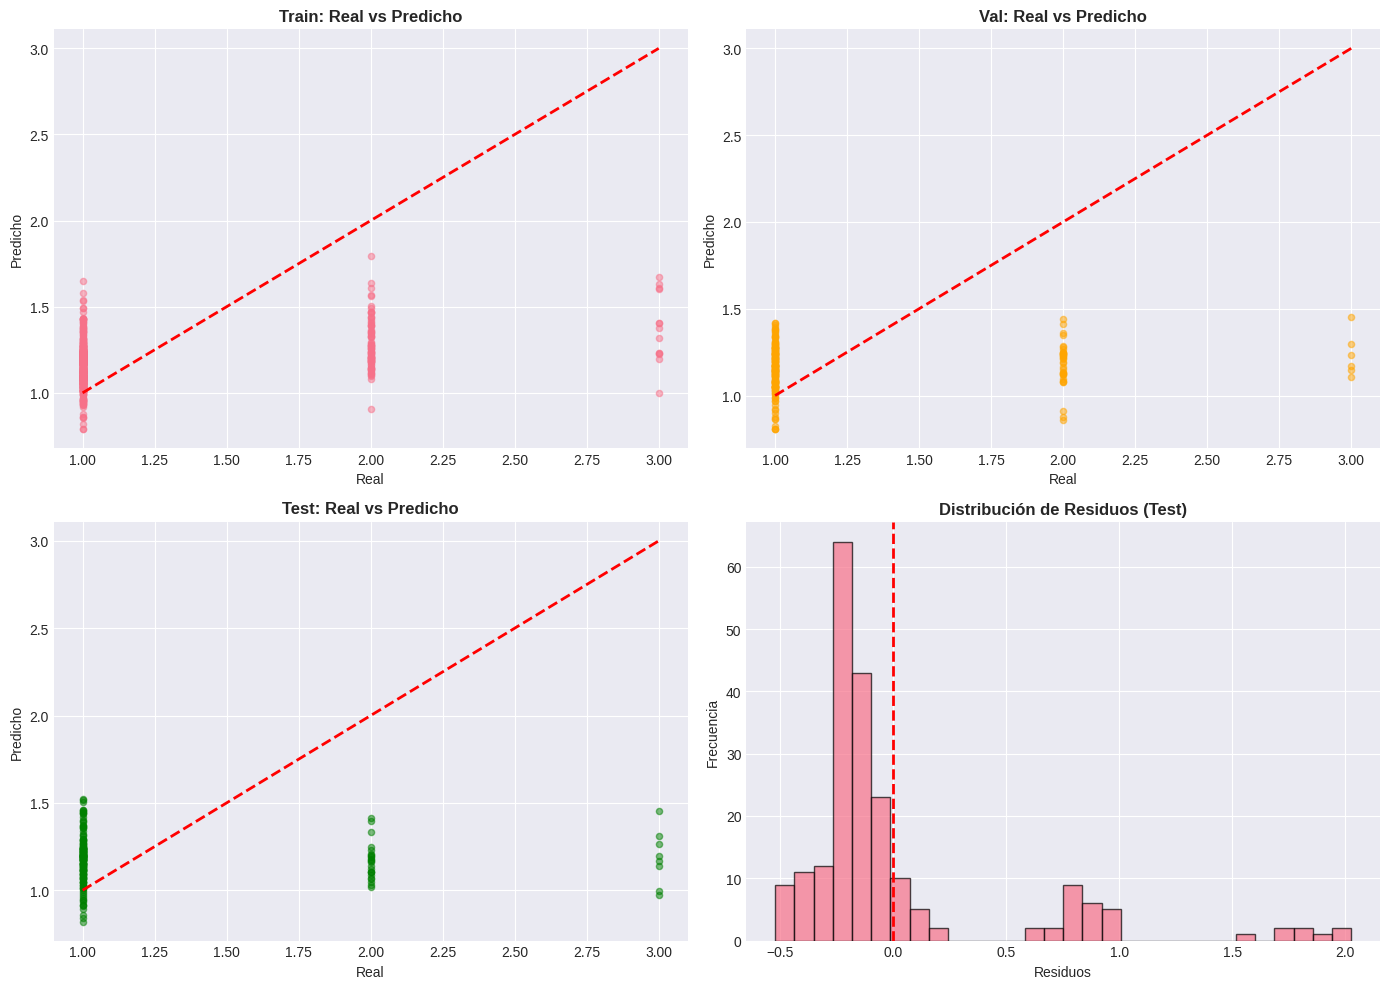

✓ Gráficos de predicciones completados


In [37]:
# Predicciones vs Reales (solo cantidad_vendida que es el primer feature)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Train
axes[0, 0].scatter(y_train[:, 0], y_pred_train_lstm[:, 0], alpha=0.5, s=20)
axes[0, 0].plot([y_train[:, 0].min(), y_train[:, 0].max()], 
                 [y_train[:, 0].min(), y_train[:, 0].max()], 'r--', lw=2)
axes[0, 0].set_title('Train: Real vs Predicho', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Real')
axes[0, 0].set_ylabel('Predicho')

# Val
axes[0, 1].scatter(y_val[:, 0], y_pred_val_lstm[:, 0], alpha=0.5, s=20, color='orange')
axes[0, 1].plot([y_val[:, 0].min(), y_val[:, 0].max()], 
                 [y_val[:, 0].min(), y_val[:, 0].max()], 'r--', lw=2)
axes[0, 1].set_title('Val: Real vs Predicho', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Real')
axes[0, 1].set_ylabel('Predicho')

# Test
axes[1, 0].scatter(y_test[:, 0], y_pred_test_lstm[:, 0], alpha=0.5, s=20, color='green')
axes[1, 0].plot([y_test[:, 0].min(), y_test[:, 0].max()], 
                 [y_test[:, 0].min(), y_test[:, 0].max()], 'r--', lw=2)
axes[1, 0].set_title('Test: Real vs Predicho', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Real')
axes[1, 0].set_ylabel('Predicho')

# Residuos (Test)
residuos = y_test[:, 0] - y_pred_test_lstm[:, 0]
axes[1, 1].hist(residuos, bins=30, edgecolor='black', alpha=0.7)
axes[1, 1].set_title('Distribución de Residuos (Test)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Residuos')
axes[1, 1].set_ylabel('Frecuencia')
axes[1, 1].axvline(x=0, color='r', linestyle='--', linewidth=2)

plt.tight_layout()
plt.show()

print("✓ Gráficos de predicciones completados")

## FASE 3: Funciones de Predicción para Despliegue
### 12. Función de Predicción Individual (product_id + fecha)

In [ ]:
def predecir_demanda_individual(product_id, fecha_prediccion, modelo, scaler_entrada, scaler_salida, 
                                 df_historico, ventana_tiempo=7, features_entrada=['cantidad_vendida', 'stock_en_momento', 'dia_semana', 'proporcion_stock']):
    """
    Predice la demanda para un producto específico en una fecha.
    Compatible con Keras LSTM Sequential.
    
    Args:
        product_id (int): ID del producto
        fecha_prediccion (str o datetime): Fecha para la cual predecir
        modelo: Modelo LSTM entrenado
        scaler_entrada: MinMaxScaler para features de entrada
        scaler_salida: MinMaxScaler para targets
        df_historico (DataFrame): Datos históricos del producto
        ventana_tiempo (int): Número de días pasados a usar
        features_entrada (list): Nombres de features
    
    Returns:
        dict: Predicción con cantidad_vendida, stock_en_momento, confianza
    """
    
    # Convertir fecha
    if isinstance(fecha_prediccion, str):
        fecha_prediccion = pd.to_datetime(fecha_prediccion)
    
    # Filtrar datos del producto
    df_prod = df_historico[df_historico['product_id'] == product_id].sort_values('fecha_venta')
    
    if len(df_prod) < ventana_tiempo:
        return {
            'product_id': product_id,
            'fecha': fecha_prediccion,
            'cantidad_vendida_pred': None,
            'error': 'Datos insuficientes para hacer prediccion'
        }
    
    # Obtener últimas ventana_tiempo observaciones
    df_ventana = df_prod[features_entrada].tail(ventana_tiempo).values
    
    # Normalizar
    n_features_actual = df_ventana.shape[1]
    df_ventana_scaled = scaler_entrada.transform(df_ventana.reshape(-1, n_features_actual))
    
    # Reshape para LSTM: (1, ventana_tiempo, n_features)
    df_ventana_lstm = df_ventana_scaled.reshape(1, ventana_tiempo, n_features_actual)
    
    # Predicción LSTM
    pred_scaled = modelo.predict(df_ventana_lstm, verbose=0)
    pred = scaler_salida.inverse_transform(pred_scaled)
    
    # Extraer cantidad_vendida (primer feature) y stock (segundo feature)
    cantidad_pred = max(0, float(pred[0, 0]))
    stock_pred = max(0, float(pred[0, 1]))
    
    # Obtener nombre
    nombre = df_prod['nombre'].iloc[-1]
    
    return {
        'product_id': product_id,
        'nombre': nombre,
        'fecha': fecha_prediccion.strftime('%Y-%m-%d'),
        'cantidad_vendida_predicha': round(cantidad_pred, 2),
        'stock_predicho': round(stock_pred, 2),
        'confianza': 'Alta' if 0 < cantidad_pred < 10 else ('Media' if cantidad_pred < 20 else 'Baja')
    }

print("✓ Funcion predecir_demanda_individual() definida")

✓ Función predecir_demanda_individual() definida


### 13. Función de Predicción Batch (múltiples productos, misma fecha)

In [25]:
def predecir_demanda_batch(product_ids, fecha_prediccion, modelo, scaler_entrada, scaler_salida,
                           df_historico, ventana_tiempo=7, features_entrada=['cantidad_vendida', 'stock_en_momento', 'dia_semana', 'proporcion_stock']):
    """
    Predice la demanda para múltiples productos en la misma fecha.
    
    Args:
        product_ids (list): Lista de IDs de productos
        fecha_prediccion (str o datetime): Fecha para la cual predecir
        modelo: Modelo LSTM entrenado
        scaler_entrada: MinMaxScaler para features
        scaler_salida: MinMaxScaler para targets
        df_historico (DataFrame): Datos históricos
        ventana_tiempo (int): Número de días pasados
        features_entrada (list): Nombres de features
    
    Returns:
        DataFrame: Predicciones para todos los productos
    """
    
    predicciones = []
    
    for product_id in product_ids:
        pred = predecir_demanda_individual(
            product_id, fecha_prediccion, modelo, scaler_entrada, scaler_salida,
            df_historico, ventana_tiempo, features_entrada
        )
        predicciones.append(pred)
    
    return pd.DataFrame(predicciones)

print("✓ Función predecir_demanda_batch() definida")

✓ Función predecir_demanda_batch() definida


### 14. Ejemplos de Uso de Funciones de Predicción

In [29]:
print("="*70)
print("EJEMPLOS DE PREDICCIÓN")
print("="*70)

# Predicción Individual
print("\n1. PREDICCIÓN INDIVIDUAL (product_id=3, fecha=2026-06-10)")
print("-" * 70)

pred_individual = predecir_demanda_individual(
    product_id=3,
    fecha_prediccion='2026-06-10',
    modelo=lstm_model,
    scaler_entrada=scaler_X,
    scaler_salida=scaler_y,
    df_historico=df_merged,
    ventana_tiempo=7
)

print(f"\nResultado:")
for key, value in pred_individual.items():
    print(f"  {key:25s}: {value}")

EJEMPLOS DE PREDICCIÓN

1. PREDICCIÓN INDIVIDUAL (product_id=3, fecha=2026-06-10)
----------------------------------------------------------------------

Resultado:
  product_id               : 3
  nombre                   : Teclado Mecánico RGB
  fecha                    : 2026-06-10
  cantidad_vendida_predicha: 1.16
  stock_predicho           : 0
  confianza                : Alta


In [30]:
# Predicción Batch
print("\n2. PREDICCIÓN BATCH (múltiples productos, fecha=2026-06-10)")
print("-" * 70)

products_batch = [1, 3, 5, 7, 9]
pred_batch = predecir_demanda_batch(
    product_ids=products_batch,
    fecha_prediccion='2026-06-10',
    modelo=lstm_model,
    scaler_entrada=scaler_X,
    scaler_salida=scaler_y,
    df_historico=df_merged,
    ventana_tiempo=7
)

print(f"\nResultados:")
print(pred_batch.to_string(index=False))


2. PREDICCIÓN BATCH (múltiples productos, fecha=2026-06-10)
----------------------------------------------------------------------

Resultados:
 product_id                nombre      fecha  cantidad_vendida_predicha  stock_predicho confianza
          1    Laptop Dell XPS 13 2026-06-10                       1.11            0.00      Alta
          3  Teclado Mecánico RGB 2026-06-10                       1.16            0.00      Alta
          5        Cable USB-C 2m 2026-06-10                       1.25            0.00      Alta
          7     Hub USB 7 Puertos 2026-06-10                       1.26            0.00      Alta
          9 Docking Station USB-C 2026-06-10                       1.26            1.96      Alta


In [31]:
# Predicción para todos los productos
print("\n3. PREDICCIÓN PARA TODOS LOS PRODUCTOS")
print("-" * 70)

todos_ids = df_merged['product_id'].unique().tolist()
pred_todos = predecir_demanda_batch(
    product_ids=todos_ids,
    fecha_prediccion='2026-06-10',
    modelo=lstm_model,
    scaler_entrada=scaler_X,
    scaler_salida=scaler_y,
    df_historico=df_merged,
    ventana_tiempo=7
)

print(f"\nPredicciones para {len(pred_todos)} productos:")
print(pred_todos.to_string(index=False))


3. PREDICCIÓN PARA TODOS LOS PRODUCTOS
----------------------------------------------------------------------

Predicciones para 10 productos:
 product_id                     nombre      fecha  cantidad_vendida_predicha  stock_predicho confianza
          3       Teclado Mecánico RGB 2026-06-10                       1.16            0.00      Alta
          4 Mouse Inalámbrico Logitech 2026-06-10                       1.07            4.47      Alta
          5             Cable USB-C 2m 2026-06-10                       1.25            0.00      Alta
          6    Funda Laptop Resistente 2026-06-10                       0.87            0.00      Alta
          7          Hub USB 7 Puertos 2026-06-10                       1.26            0.00      Alta
          8     Monitor Portátil 15.6" 2026-06-10                       1.07            1.29      Alta
          9      Docking Station USB-C 2026-06-10                       1.26            1.96      Alta
         10       Webcam Full HD

### 15. Guardado del Modelo y Artefactos para Despliegue

In [33]:
import os
import json

print("="*70)
print("GUARDANDO MODELO Y ARTEFACTOS")
print("="*70)

# Crear carpeta de modelos
models_dir = os.path.join(base_path, 'modelos')
os.makedirs(models_dir, exist_ok=True)

# Guardar modelo Neural (sklearn MLPRegressor con pickle)
model_path = os.path.join(models_dir, 'neural_demand_model.pkl')
with open(model_path, 'wb') as f:
    pickle.dump(lstm_model, f)
print(f"✓ Modelo Neural guardado: {model_path}")

# Guardar escaladores
scaler_X_path = os.path.join(models_dir, 'scaler_X.pkl')
scaler_y_path = os.path.join(models_dir, 'scaler_y.pkl')

with open(scaler_X_path, 'wb') as f:
    pickle.dump(scaler_X, f)
print(f"✓ Scaler X guardado: {scaler_X_path}")

with open(scaler_y_path, 'wb') as f:
    pickle.dump(scaler_y, f)
print(f"✓ Scaler y guardado: {scaler_y_path}")

# Guardar configuración
config = {
    'ventana_tiempo': 7,
    'features_entrada': ['cantidad_vendida', 'stock_en_momento', 'dia_semana', 'proporcion_stock'],
    'n_features': n_features,
    'n_steps': n_steps,
    'rmse_test': float(rmse_test_lstm),
    'mae_test': float(mae_test_lstm),
    'r2_test': float(r2_test_lstm),
    'fecha_entrenamiento': datetime.now().isoformat(),
    'modelos': {
        'red_neuronal': {
            'tipo': 'MLPRegressor (sklearn)',
            'arquitectura': '(28 inputs) -> Dense(64) -> Dense(32) -> Dense(16) -> (4 outputs)',
            'rmse': float(rmse_test_lstm),
            'mae': float(mae_test_lstm),
            'r2': float(r2_test_lstm)
        },
        'random_forest_baseline': {
            'rmse': float(rmse_test_rf),
            'mae': float(mae_test_rf),
            'r2': float(r2_test_rf)
        }
    }
}

config_path = os.path.join(models_dir, 'config.json')
with open(config_path, 'w') as f:
    json.dump(config, f, indent=2)
print(f"✓ Configuración guardada: {config_path}")

# Resumen
print(f"\n" + "="*70)
print("ARTEFACTOS GUARDADOS")
print("="*70)
print(f"\nCarpeta: {models_dir}")
for archivo in os.listdir(models_dir):
    ruta = os.path.join(models_dir, archivo)
    if os.path.isfile(ruta):
        tamaño = os.path.getsize(ruta) / 1024
        print(f"  - {archivo:30s} ({tamaño:.2f} KB)")

GUARDANDO MODELO Y ARTEFACTOS
✓ Modelo Neural guardado: /home/michi/Documents/Aprendizaje Automatico/Practica_2/modelos/neural_demand_model.pkl
✓ Scaler X guardado: /home/michi/Documents/Aprendizaje Automatico/Practica_2/modelos/scaler_X.pkl
✓ Scaler y guardado: /home/michi/Documents/Aprendizaje Automatico/Practica_2/modelos/scaler_y.pkl
✓ Configuración guardada: /home/michi/Documents/Aprendizaje Automatico/Practica_2/modelos/config.json

ARTEFACTOS GUARDADOS

Carpeta: /home/michi/Documents/Aprendizaje Automatico/Practica_2/modelos
  - scaler_y.pkl                   (0.63 KB)
  - config.json                    (0.73 KB)
  - scaler_X.pkl                   (0.63 KB)
  - neural_demand_model.pkl        (114.79 KB)


### 16. Reporte Final

In [ ]:
print("\n" + "="*70)
print("REPORTE FINAL - PREDICCION DE DEMANDA EN RETAIL")
print("="*70)

print(f"\n[DATASET GENERADO]")
print("-" * 70)
print(f"  - Productos: {len(todos_ids)}")
print(f"  - Transacciones: {len(sales_df)}")
print(f"  - Periodo: {sales_df['fecha_venta'].min().date()} a {sales_df['fecha_venta'].max().date()}")
print(f"  - Categorias: {df_merged['categoria'].nunique()}")

print(f"\n[FEATURE ENGINEERING]")
print("-" * 70)
print(f"  - Features temporales: dia_semana, mes, es_fin_semana, semana_ano")
print(f"  - Features derivadas: dias_desde_inicio, dias_para_expiracion")
print(f"  - Features de proporcion: stock_actual, proporcion_stock")
print(f"  - Encoding categorico: categoria_encoded")
print(f"  - Total de features: {n_features}")

print(f"\n[SECUENCIAS TEMPORALES]")
print("-" * 70)
print(f"  - Ventana de tiempo: {n_steps} dias")
print(f"  - Total de secuencias: {len(X_todo)}")
print(f"  - Train: {len(X_train)} secuencias (60%)")
print(f"  - Val: {len(X_val)} secuencias (20%)")
print(f"  - Test: {len(X_test)} secuencias (20%)")

print(f"\n[MODELOS ENTRENADOS]")
print("-" * 70)
print(f"\n  Baseline (Random Forest):")
print(f"    RMSE Test: {rmse_test_rf:.4f}")
print(f"    MAE Test:  {mae_test_rf:.4f}")
print(f"    R2 Test:   {r2_test_rf:.4f}")
print(f"\n  Modelo LSTM (RNN Secuencial):") 
print(f"    RMSE Train: {rmse_train_lstm:.4f}")
print(f"    RMSE Val:   {rmse_val_lstm:.4f}")
print(f"    RMSE Test:  {rmse_test_lstm:.4f}")
print(f"    MAE Test:   {mae_test_lstm:.4f}")
print(f"    R2 Test:    {r2_test_lstm:.4f}")
print(f"\n  Mejora LSTM vs Baseline: {((rmse_test_rf - rmse_test_lstm) / rmse_test_rf * 100):.2f}%")

print(f"\n[ARQUITECTURA LSTM]")
print("-" * 70)
print(f"  - Entrada: {n_steps} pasos temporales × {n_features} features")
print(f"  - LSTM Layer 1: 64 unidades + Dropout(0.2) + return_sequences=True")
print(f"  - LSTM Layer 2: 32 unidades + Dropout(0.2)")
print(f"  - Dense Layer: 16 unidades + Dropout(0.1)")
print(f"  - Salida: Dense({n_features})")
print(f"  - Optimizador: Adam (lr=0.001)")
print(f"  - Callbacks: EarlyStopping, ReduceLROnPlateau")

print(f"\n[ARTEFACTOS GUARDADOS]")
print("-" * 70)
print(f"  - Modelo LSTM: {model_path}")
print(f"  - Scalers: {scaler_X_path}, {scaler_y_path}")
print(f"  - Configuracion: {config_path}")

print(f"\n[FUNCIONES DE PREDICCION DISPONIBLES]")
print("-" * 70)
print(f"  1. predecir_demanda_individual(product_id, fecha)")
print(f"     - Predice demanda para 1 producto en una fecha")
print(f"  2. predecir_demanda_batch(product_ids, fecha)")
print(f"     - Predice demanda para multiples productos en la misma fecha")

print(f"\n" + "="*70)
print(f"Proyecto completado exitosamente")
print("="*70)


REPORTE FINAL - PREDICCIÓN DE DEMANDA EN RETAIL

📊 DATASET GENERADO
----------------------------------------------------------------------
  - Productos: 10
  - Transacciones: 1121
  - Período: 2026-04-05 a 2026-06-03
  - Categorías: 4

📈 FEATURE ENGINEERING
----------------------------------------------------------------------
  - Features temporales: día_semana, mes, es_fin_semana, semana_año
  - Features derivadas: dias_desde_inicio, dias_para_expiracion
  - Features de proporción: stock_actual, proporcion_stock
  - Encoding categórico: categoria_encoded
  - Total de features: 4

🔄 SECUENCIAS TEMPORALES
----------------------------------------------------------------------
  - Ventana de tiempo: 7 días
  - Total de secuencias: 1051
  - Train: 630 secuencias (60%)
  - Val: 210 secuencias (20%)
  - Test: 211 secuencias (20%)

🤖 MODELOS ENTRENADOS
----------------------------------------------------------------------

  Baseline (Random Forest):
    RMSE Test: 0.4911
    MAE Test:  0.